Incident_ID                     0
Affected_Line_Length_km         0
Fault_Category                 30
Grid_Load_Level                30
Dispatch_Window                30
Crew_Type                       0
Dispatch_Delay_Minutes          0
Technician_Experience_Years    30
Restoration_Time_Minutes        0
dtype: int64

Train
mean sqaured train  117.48811472546257
mean absolute error  6.609999613045602
r2 train  0.762996614677848

Test
mean sqaured test  77.82608297045272
mean absolute error  5.89958267601809
r2 test  0.8263690332995851

Initial cost: 1529.3165131909711
Final cost: 58.74405736273128
Cost at iteration 1000: 58.74405736273128
Cost at iteration 5000: 58.74405736273128


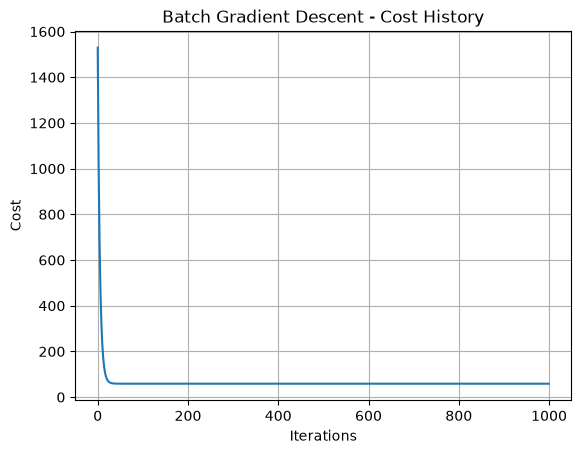

'\nsgd_model = SGDRegressor(\n    alpha=0.0001,\n    warm_start=True,\n    max_iter=1,\n    tol=None,  \n    eta0=0.01,\n    random_state=42,\n)\n\n\nn_iterations = 1000\ncost_history = []\ny_train_flat = y_train.values.ravel()\ny_test_flat = y_test.values.ravel()\n\nfor i in range(n_iterations):\n\n  sgd_model.partial_fit(X_train_scaled, y_train_flat)\n\n  y_pred = sgd_model.predict(X_test_scaled)\n  cost = (\n      mean_squared_error(y_test_flat, y_pred) / 2\n  ) \n  cost_history.append(cost)\n\n\nmae = mean_absolute_error(y_test_flat, y_pred)\nr2 = r2_score(y_test_flat, y_pred)\n\nprint(f"Optimized Weights (coef): {sgd_model.coef_}")\nprint(f"Mean Absolute Error: {mae:.4f}")\nprint(f"R² Score : {r2:.4f}")\n\n\nplt.figure(figsize=(8, 5))\nplt.plot(range(n_iterations), cost_history, color="b", lw=2)\nplt.title("Training Cost over Iterations (SGDRegressor)")\nplt.xlabel("Iterations (Epochs)")\nplt.ylabel("Mean Squared Error (Cost)")\nplt.grid(True)\nplt.show()\n'

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("grid_restoration.csv")

print(df.isnull().sum())
y = df[["Restoration_Time_Minutes"]]
df = df.drop(columns=["Incident_ID", "Restoration_Time_Minutes"])


df["Technician_Experience_Years"] = df["Technician_Experience_Years"].fillna(
    df["Technician_Experience_Years"].median()
)

for col in ["Fault_Category", "Grid_Load_Level", "Dispatch_Window"]:
  df[col] = df[col].fillna(df[col].mode()[0])


load_mapping = {"Low": 0, "Medium": 1, "High": 2}
df["Grid_Load_Level"] = df["Grid_Load_Level"].map(load_mapping)

df_encoded = pd.get_dummies(
    df, columns=["Fault_Category", "Dispatch_Window", "Crew_Type"], drop_first=True
)

bool_cols = df_encoded.select_dtypes(include=["bool"]).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    df_encoded, y, test_size=0.20, random_state=42
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


def compute_cost(X,y,theta):
    m = len(y)
    predictions = X.dot(theta)
    cost = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return cost

def batch_gradient_descent(X, y, theta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for _ in range(iterations):
        gradients = (1 / m) * X.T.dot(X.dot(theta) - y)
        theta = theta - learning_rate * gradients
        cost_history.append(compute_cost(X,y,theta))

    return theta ,cost_history
  




X_train_array = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
theta = np.zeros(X_train_array.shape[1])

theta ,cost_history = batch_gradient_descent(
    X_train_array,
    y_train.values.ravel(),
    theta,
    learning_rate=0.1,
    iterations=1000
)

X_test_array = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

y_train_pred = X_train_array.dot(theta)

y_pred = X_test_array.dot(theta)

print()
print("Train")
print("mean sqaured train ",mean_squared_error(y_train,y_train_pred))
print("mean absolute error ",mean_absolute_error(y_train,y_train_pred))
print("r2 train ",r2_score(y_train,y_train_pred))

print()
print("Test")
print("mean sqaured test ",mean_squared_error(y_test,y_pred))
print("mean absolute error ",mean_absolute_error(y_test,y_pred))
print("r2 test ",r2_score(y_test,y_pred))
print()

print("Initial cost:", cost_history[0])
print("Final cost:", cost_history[-1])
print("Cost at iteration 1000:", cost_history[999])
print("Cost at iteration 5000:", cost_history[-1])

plt.plot(cost_history)
plt.title("Batch Gradient Descent - Cost History")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.grid()
plt.show()


"""
sgd_model = SGDRegressor(
    alpha=0.0001,
    warm_start=True,
    max_iter=1,
    tol=None,  
    eta0=0.01,
    random_state=42,
)


n_iterations = 1000
cost_history = []
y_train_flat = y_train.values.ravel()
y_test_flat = y_test.values.ravel()

for i in range(n_iterations):

  sgd_model.partial_fit(X_train_scaled, y_train_flat)

  y_pred = sgd_model.predict(X_test_scaled)
  cost = (
      mean_squared_error(y_test_flat, y_pred) / 2
  ) 
  cost_history.append(cost)


mae = mean_absolute_error(y_test_flat, y_pred)
r2 = r2_score(y_test_flat, y_pred)

print(f"Optimized Weights (coef): {sgd_model.coef_}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"R² Score : {r2:.4f}")


plt.figure(figsize=(8, 5))
plt.plot(range(n_iterations), cost_history, color="b", lw=2)
plt.title("Training Cost over Iterations (SGDRegressor)")
plt.xlabel("Iterations (Epochs)")
plt.ylabel("Mean Squared Error (Cost)")
plt.grid(True)
plt.show()
"""

[38.92090738587415, 38.92090738587414, 38.92090738587414, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587412, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587415, 38.92090738587414, 38.920907385874145, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587412, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587415, 38.92090738587414, 38.920907385874145, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.9

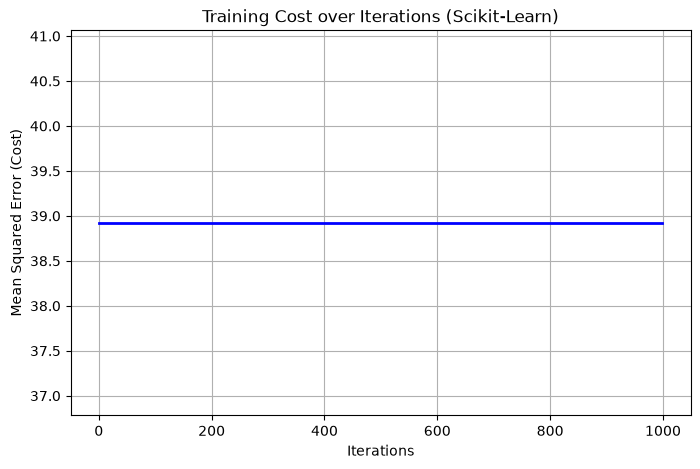

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score,mean_squared_error
import matplotlib.pyplot as plt

df = pd.read_csv('grid_restoration.csv')

y = df[['Restoration_Time_Minutes']]
df = df.drop(columns=['Incident_ID','Restoration_Time_Minutes'])





df['Technician_Experience_Years'] = df[
    'Technician_Experience_Years'
].fillna(df['Technician_Experience_Years'].median())

# Categorical columns
for col in ['Fault_Category', 'Grid_Load_Level', 'Dispatch_Window']:
    df[col] = df[col].fillna(df[col].mode()[0])







nominal_categorical_column = ['Fault_Category','Dispatch_Window','Crew_Type']



load_mapping = {"Low": 0, "Medium": 1, "High": 2}
#df["Grid_Load_Level_Encoded"] = df["Grid_Load_Level"].map(load_mapping)
df["Grid_Load_Level"] = df["Grid_Load_Level"].map(load_mapping)




df_encoded = pd.get_dummies(df,columns=['Fault_Category','Dispatch_Window','Crew_Type'],drop_first=True)


bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)




X_train, X_test, y_train, y_test = train_test_split(df_encoded,y,test_size=0.20,random_state=42 )



model = make_pipeline(StandardScaler(),SGDRegressor(alpha=0.0001,  warm_start=True , max_iter=1000,tol=None,eta0=0.01,random_state=42))

cost_history = []
for i in range(1000):

    
    model.fit(X_train, y_train.values.ravel())
    y_pred = model.predict(X_test)
    cost = mean_squared_error(y_test, y_pred) / 2  # Divided by 2 to match standard cost convention
    cost_history.append(cost)
print(cost_history)



mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Optimized Weights (coef): {model.named_steps["sgdregressor"].coef_}")

print(f"Mean Absolute Error: {mae:.4f}")
print(f"R² Score : {r2:.4f}")


plt.figure(figsize=(8, 5))
plt.plot(range(1000), cost_history, color="b", lw=2)
plt.title("Training Cost over Iterations (Scikit-Learn)")
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (Cost)")
plt.grid(True)
plt.show()

